In [1]:

# Step 1: Download YESNO Dataset

import os
import urllib.request
import tarfile

url = "https://www.openslr.org/resources/1/waves_yesno.tar.gz"

os.makedirs("/content/YESNO", exist_ok=True)

archive_path = "/content/YESNO/waves_yesno.tar.gz"

urllib.request.urlretrieve(url, archive_path)

with tarfile.open(archive_path, "r:gz") as archive:
    archive.extractall("/content/YESNO", filter="data")

folder = "/content/YESNO/waves_yesno"

wav_files = [
    f for f in os.listdir(folder)
    if f.endswith(".wav")
]

print("Dataset downloaded successfully!")
print("Number of recordings:", len(wav_files))
print("First recording:", wav_files[0])


Dataset downloaded successfully!
Number of recordings: 60
First recording: 1_0_1_1_0_1_1_1.wav


In [2]:

# Step 2: Listen to an audio recording

import librosa
import numpy as np
from IPython.display import Audio, display

# Select the first audio file
audio_file = sorted(wav_files)[0]
audio_path = os.path.join(folder, audio_file)

# Load audio
audio_data, sr = librosa.load(audio_path, sr=None)

# Extract labels from filename
labels = audio_file.replace(".wav", "").split("_")
labels = ["Yes" if x == "1" else "No" for x in labels]

print("Audio File:", audio_file)
print("Sample Rate:", sr, "Hz")
print("Duration:", round(len(audio_data) / sr, 2), "seconds")
print("Labels:", labels)

# Play audio
display(Audio(audio_data, rate=sr))


Audio File: 0_0_0_0_1_1_1_1.wav
Sample Rate: 8000 Hz
Duration: 6.35 seconds
Labels: ['No', 'No', 'No', 'No', 'Yes', 'Yes', 'Yes', 'Yes']


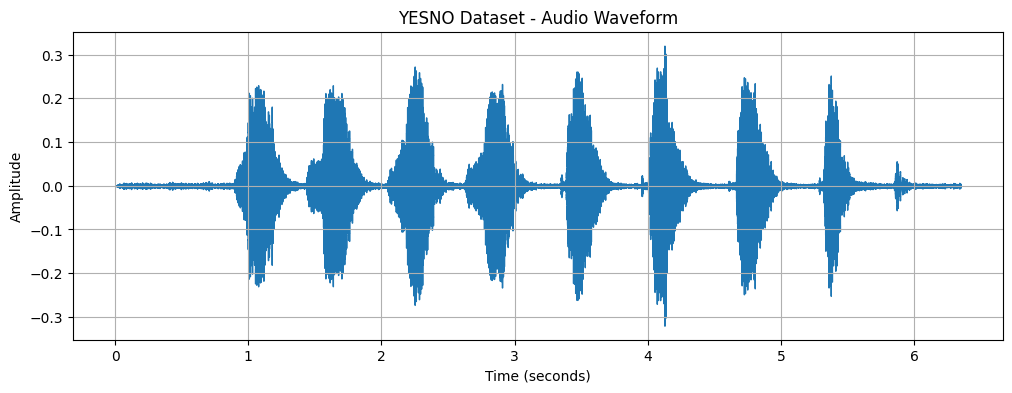

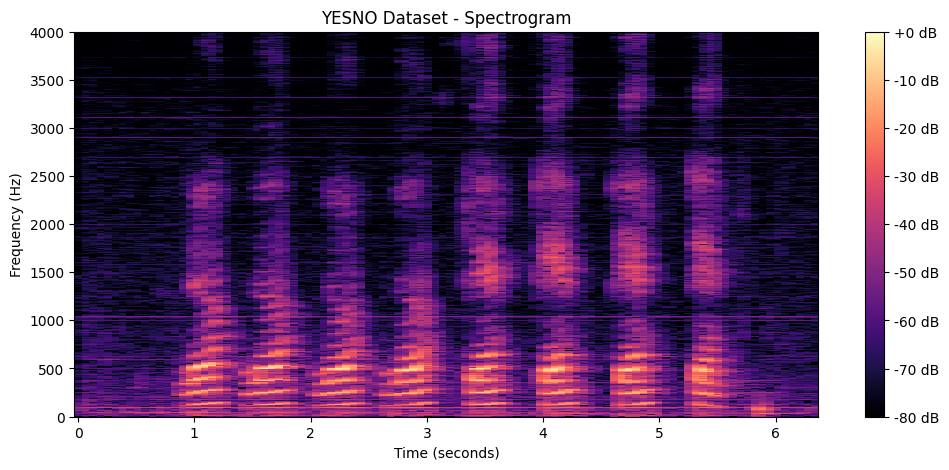

In [3]:

# Step 3: Waveform and Spectrogram

import matplotlib.pyplot as plt
import librosa.display
import numpy as np

# 1. Plot Waveform
plt.figure(figsize=(12, 4))
librosa.display.waveshow(audio_data, sr=sr)
plt.title("YESNO Dataset - Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

# 2. Plot Spectrogram
D = librosa.stft(audio_data)
D_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

plt.figure(figsize=(12, 5))
librosa.display.specshow(
    D_db,
    sr=sr,
    x_axis="time",
    y_axis="hz",
    cmap="magma"
)
plt.colorbar(format="%+2.0f dB")
plt.title("YESNO Dataset - Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.show()


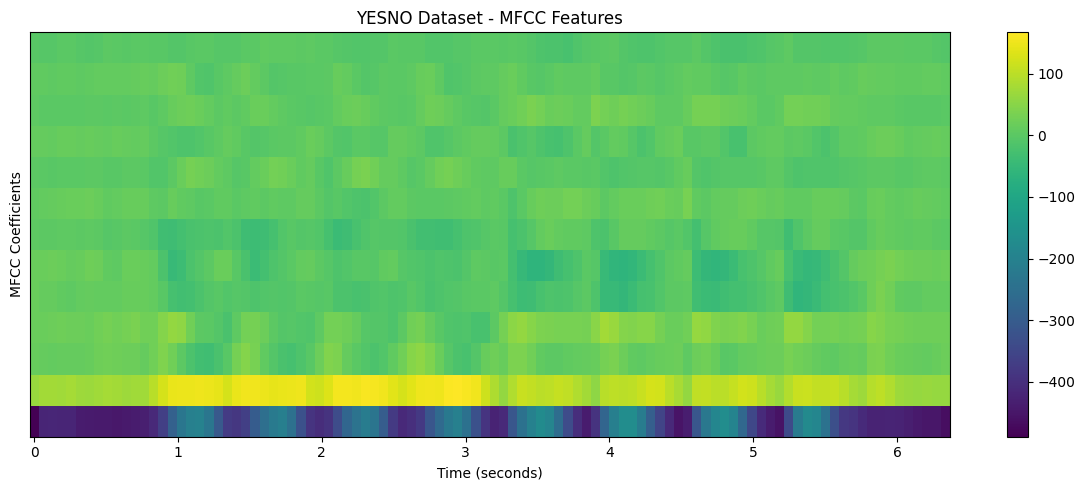

MFCC Shape: (13, 100)
Number of MFCC coefficients: 13


In [4]:

# Step 4: MFCC Feature Extraction

import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

# Extract 13 MFCC features
mfcc = librosa.feature.mfcc(
    y=audio_data,
    sr=sr,
    n_mfcc=13
)

# Display MFCC
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mfcc,
    sr=sr,
    x_axis="time",
    cmap="viridis"
)

plt.colorbar()
plt.title("YESNO Dataset - MFCC Features")
plt.xlabel("Time (seconds)")
plt.ylabel("MFCC Coefficients")
plt.tight_layout()
plt.show()

print("MFCC Shape:", mfcc.shape)
print("Number of MFCC coefficients:", mfcc.shape[0])


In [5]:

# Step 5: Prepare Dataset for Classification

import os
import librosa
import numpy as np
from collections import Counter

X = []
y = []

for filename in sorted(wav_files):

    audio_path = os.path.join(folder, filename)

    # Load audio
    audio, sample_rate = librosa.load(
        audio_path, sr=None
    )

    # Extract MFCC
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sample_rate,
        n_mfcc=13
    )

    # Convert MFCC to fixed-size features
    features = np.concatenate([
        np.mean(mfcc, axis=1),
        np.std(mfcc, axis=1)
    ])

    # Extract the 8 Yes/No labels
    labels = filename.replace(".wav", "").split("_")

    X.append(features)
    y.append("_".join(labels))

X = np.array(X)
y = np.array(y)

print("Dataset prepared successfully!")
print("Number of recordings:", len(X))
print("Features shape:", X.shape)
print("Number of unique label patterns:", len(set(y)))
print("Label distribution:", Counter(y))


Dataset prepared successfully!
Number of recordings: 60
Features shape: (60, 26)
Number of unique label patterns: 60
Label distribution: Counter({np.str_('0_0_0_0_1_1_1_1'): 1, np.str_('0_0_0_1_0_0_0_1'): 1, np.str_('0_0_0_1_0_1_1_0'): 1, np.str_('0_0_1_0_0_0_1_0'): 1, np.str_('0_0_1_0_0_1_1_0'): 1, np.str_('0_0_1_0_0_1_1_1'): 1, np.str_('0_0_1_0_1_0_0_0'): 1, np.str_('0_0_1_0_1_0_0_1'): 1, np.str_('0_0_1_0_1_0_1_1'): 1, np.str_('0_0_1_1_0_0_0_1'): 1, np.str_('0_0_1_1_0_1_0_0'): 1, np.str_('0_0_1_1_0_1_1_0'): 1, np.str_('0_0_1_1_0_1_1_1'): 1, np.str_('0_0_1_1_1_0_0_0'): 1, np.str_('0_0_1_1_1_0_0_1'): 1, np.str_('0_0_1_1_1_1_0_0'): 1, np.str_('0_0_1_1_1_1_1_0'): 1, np.str_('0_1_0_0_0_1_0_0'): 1, np.str_('0_1_0_0_0_1_1_0'): 1, np.str_('0_1_0_0_1_0_1_0'): 1, np.str_('0_1_0_0_1_0_1_1'): 1, np.str_('0_1_0_1_0_0_0_0'): 1, np.str_('0_1_0_1_1_0_1_0'): 1, np.str_('0_1_0_1_1_1_0_0'): 1, np.str_('0_1_1_0_0_1_1_0'): 1, np.str_('0_1_1_0_0_1_1_1'): 1, np.str_('0_1_1_1_0_0_0_0'): 1, np.str_('0_1_1_1_

In [6]:

# Step 6: Segment Yes/No words and extract MFCC

import os
import librosa
import numpy as np
from collections import Counter

X_words = []
y_words = []
issues = []

for filename in sorted(wav_files):

    path = os.path.join(folder, filename)
    audio, sample_rate = librosa.load(path, sr=None)

    labels = [int(v) for v in filename[:-4].split("_")]

    # Detect non-silent audio intervals
    intervals = librosa.effects.split(
        audio,
        top_db=25,
        frame_length=512,
        hop_length=128
    )

    # Only use recordings with exactly 8 segments
    if len(intervals) != 8:
        issues.append((filename, len(intervals)))
        continue

    for (start, end), label in zip(intervals, labels):

        word = audio[start:end]

        mfcc = librosa.feature.mfcc(
            y=word,
            sr=sample_rate,
            n_mfcc=13
        )

        features = np.concatenate([
            np.mean(mfcc, axis=1),
            np.std(mfcc, axis=1)
        ])

        X_words.append(features)
        y_words.append(label)

X_words = np.array(X_words)
y_words = np.array(y_words)

print("Word samples:", len(X_words))
print("Feature shape:", X_words.shape)
print("Labels:", Counter(y_words))
print("Skipped recordings:", len(issues))
print("First skipped examples:", issues[:5])


/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1920
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=384
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=256
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=512
  warnings.warn(


Word samples: 328
Feature shape: (328, 26)
Labels: Counter({np.int64(1): 176, np.int64(0): 152})
Skipped recordings: 19
First skipped examples: [('0_0_0_0_1_1_1_1.wav', 9), ('0_0_0_1_0_0_0_1.wav', 9), ('0_0_1_0_1_0_0_1.wav', 7), ('0_0_1_1_0_0_0_1.wav', 9), ('0_0_1_1_1_0_0_0.wav', 7)]


In [7]:

# Step 6: Segment Yes/No words and extract MFCC

import os
import librosa
import numpy as np
from collections import Counter

X_words = []
y_words = []
issues = []

for filename in sorted(wav_files):

    path = os.path.join(folder, filename)
    audio, sample_rate = librosa.load(path, sr=None)

    labels = [int(v) for v in filename[:-4].split("_")]

    # Detect non-silent audio intervals
    intervals = librosa.effects.split(
        audio,
        top_db=25,
        frame_length=512,
        hop_length=128
    )

    # Only use recordings with exactly 8 segments
    if len(intervals) != 8:
        issues.append((filename, len(intervals)))
        continue

    for (start, end), label in zip(intervals, labels):

        word = audio[start:end]

        mfcc = librosa.feature.mfcc(
            y=word,
            sr=sample_rate,
            n_mfcc=13
        )

        features = np.concatenate([
            np.mean(mfcc, axis=1),
            np.std(mfcc, axis=1)
        ])

        X_words.append(features)
        y_words.append(label)

X_words = np.array(X_words)
y_words = np.array(y_words)

print("Word samples:", len(X_words))
print("Feature shape:", X_words.shape)
print("Labels:", Counter(y_words))
print("Skipped recordings:", len(issues))
print("First skipped examples:", issues[:5])


Word samples: 328
Feature shape: (328, 26)
Labels: Counter({np.int64(1): 176, np.int64(0): 152})
Skipped recordings: 19
First skipped examples: [('0_0_0_0_1_1_1_1.wav', 9), ('0_0_0_1_0_0_0_1.wav', 9), ('0_0_1_0_1_0_0_1.wav', 7), ('0_0_1_1_0_0_0_1.wav', 9), ('0_0_1_1_1_0_0_0.wav', 7)]


In [8]:

# Step 7: Check audio segmentation

from IPython.display import Audio, display
import librosa
import os

for filename in sorted(wav_files):
    path = os.path.join(folder, filename)
    audio, sample_rate = librosa.load(path, sr=None)

    intervals = librosa.effects.split(
        audio,
        top_db=25,
        frame_length=512,
        hop_length=128
    )

    if len(intervals) == 8:
        labels = filename[:-4].split("_")

        print("Recording:", filename)

        for i, ((start, end), label) in enumerate(
            zip(intervals, labels), start=1
        ):
            print(
                f"Word {i}:",
                "Yes" if label == "1" else "No"
            )
            display(Audio(
                audio[start:end],
                rate=sample_rate
            ))

        break


Recording: 0_0_0_1_0_1_1_0.wav
Word 1: No


Word 2: No


Word 3: No


Word 4: Yes


Word 5: No


Word 6: Yes


Word 7: Yes


Word 8: No


In [9]:

# Step 7: Check audio segmentation

from IPython.display import Audio, display
import librosa
import os

for filename in sorted(wav_files):
    path = os.path.join(folder, filename)
    audio, sample_rate = librosa.load(path, sr=None)

    intervals = librosa.effects.split(
        audio,
        top_db=25,
        frame_length=512,
        hop_length=128
    )

    if len(intervals) == 8:
        labels = filename[:-4].split("_")

        print("Recording:", filename)

        for i, ((start, end), label) in enumerate(
            zip(intervals, labels), start=1
        ):
            print(
                f"Word {i}:",
                "Yes" if label == "1" else "No"
            )
            display(Audio(
                audio[start:end],
                rate=sample_rate
            ))

        break


Recording: 0_0_0_1_0_1_1_0.wav
Word 1: No


Word 2: No


Word 3: No


Word 4: Yes


Word 5: No


Word 6: Yes


Word 7: Yes


Word 8: No


Total word samples: 328
Number of features: 26
Class distribution: Counter({np.int64(1): 176, np.int64(0): 152})
Missing values: 0
Infinite values: 0


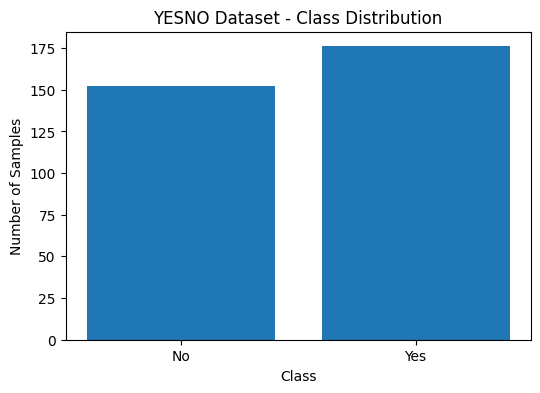

In [10]:

# Step 8: Check the dataset before training

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

print("Total word samples:", len(X_words))
print("Number of features:", X_words.shape[1])
print("Class distribution:", Counter(y_words))
print("Missing values:", np.isnan(X_words).sum())
print("Infinite values:", np.isinf(X_words).sum())

# Plot class distribution
counts = Counter(y_words)

plt.figure(figsize=(6, 4))
plt.bar(
    ["No", "Yes"],
    [counts.get(0, 0), counts.get(1, 0)]
)
plt.title("YESNO Dataset - Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.show()


In [11]:

# Step 9: Train the first classifier (SVM)

import numpy as np
import librosa
import os

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Split original recordings first
train_files, test_files = train_test_split(
    sorted(wav_files),
    test_size=0.25,
    random_state=42
)

def extract_word_features(file_list):
    features_list = []
    labels_list = []

    for filename in file_list:
        path = os.path.join(folder, filename)
        audio, sample_rate = librosa.load(path, sr=None)

        intervals = librosa.effects.split(
            audio, top_db=25,
            frame_length=512, hop_length=128
        )

        if len(intervals) != 8:
            continue

        labels = [int(x) for x in filename[:-4].split("_")]

        for (start, end), label in zip(intervals, labels):
            word = audio[start:end]

            mfcc = librosa.feature.mfcc(
                y=word, sr=sample_rate, n_mfcc=13
            )

            features = np.concatenate([
                np.mean(mfcc, axis=1),
                np.std(mfcc, axis=1)
            ])

            features_list.append(features)
            labels_list.append(label)

    return np.array(features_list), np.array(labels_list)

X_train, y_train = extract_word_features(train_files)
X_test, y_test = extract_word_features(test_files)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Train SVM
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", random_state=42)
)

svm_model.fit(X_train, y_train)

# Evaluate SVM
y_pred = svm_model.predict(X_test)

svm_accuracy = accuracy_score(y_test, y_pred)

print("\nSVM Accuracy:", round(svm_accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["No", "Yes"],
    zero_division=0
))


Training samples: 248
Testing samples: 80

SVM Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00        37
         Yes       1.00      1.00      1.00        43

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



In [12]:

# Step 10: Neural Network Classification

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

# Create Neural Network model
nn_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=42
    )
)

# Train Neural Network
nn_model.fit(X_train, y_train)

# Predict test samples
nn_predictions = nn_model.predict(X_test)

# Calculate accuracy
nn_accuracy = accuracy_score(y_test, nn_predictions)

print("Neural Network Accuracy:",
      round(nn_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    nn_predictions,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0
))

# Compare SVM and Neural Network
print("\nModel Comparison:")
print("SVM Accuracy:", round(svm_accuracy * 100, 2), "%")
print("Neural Network Accuracy:", round(nn_accuracy * 100, 2), "%")


Neural Network Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00        37
         Yes       1.00      1.00      1.00        43

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80


Model Comparison:
SVM Accuracy: 100.0 %
Neural Network Accuracy: 100.0 %


In [13]:

# Step 11: Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0
))

print("\nModel Comparison:")
print("SVM:", round(svm_accuracy * 100, 2), "%")
print("Neural Network:", round(nn_accuracy * 100, 2), "%")
print("Random Forest:", round(rf_accuracy * 100, 2), "%")


Random Forest Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00        37
         Yes       1.00      1.00      1.00        43

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80


Model Comparison:
SVM: 100.0 %
Neural Network: 100.0 %
Random Forest: 100.0 %


In [14]:

# Step 11: Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0
))

print("\nModel Comparison:")
print("SVM:", round(svm_accuracy * 100, 2), "%")
print("Neural Network:", round(nn_accuracy * 100, 2), "%")
print("Random Forest:", round(rf_accuracy * 100, 2), "%")


Random Forest Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00        37
         Yes       1.00      1.00      1.00        43

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80


Model Comparison:
SVM: 100.0 %
Neural Network: 100.0 %
Random Forest: 100.0 %


In [15]:

# Step 12: K-Nearest Neighbors (KNN)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Train KNN
knn_model.fit(X_train, y_train)

# Test KNN
knn_predictions = knn_model.predict(X_test)

knn_accuracy = accuracy_score(y_test, knn_predictions)

print("KNN Accuracy:", round(knn_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    knn_predictions,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0
))

print("\nFinal Model Comparison:")
print("SVM:", round(svm_accuracy * 100, 2), "%")
print("Neural Network:", round(nn_accuracy * 100, 2), "%")
print("Random Forest:", round(rf_accuracy * 100, 2), "%")
print("KNN:", round(knn_accuracy * 100, 2), "%")


KNN Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00        37
         Yes       1.00      1.00      1.00        43

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80


Final Model Comparison:
SVM: 100.0 %
Neural Network: 100.0 %
Random Forest: 100.0 %
KNN: 100.0 %


In [16]:

# Step 13: Check possible data leakage

import numpy as np
from sklearn.metrics import confusion_matrix

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining labels:")
print(np.unique(y_train, return_counts=True))

print("\nTesting labels:")
print(np.unique(y_test, return_counts=True))

# Check identical feature vectors across train/test
duplicates = 0

for test_sample in X_test:
    if np.any(np.all(np.isclose(
        X_train, test_sample,
        rtol=1e-7,
        atol=1e-9
    ), axis=1)):
        duplicates += 1

print("\nNear-identical train/test features:", duplicates)

print("\nSVM Confusion Matrix:")
print(confusion_matrix(y_test, svm_model.predict(X_test)))


Training samples: 248
Testing samples: 80

Training labels:
(array([0, 1]), array([115, 133]))

Testing labels:
(array([0, 1]), array([37, 43]))

Near-identical train/test features: 0

SVM Confusion Matrix:
[[37  0]
 [ 0 43]]


In [17]:

# Step 14: Inspect segmentation quality

from collections import Counter

print("Total recordings:", len(wav_files))
print("Accepted recordings:", len(wav_files) - len(issues))
print("Skipped recordings:", len(issues))

print("\nDetected segment counts:")
print(Counter(count for name, count in issues))

print("\nSkipped files:")
for filename, count in issues:
    print(filename, ":", count, "segments")


Total recordings: 60
Accepted recordings: 41
Skipped recordings: 19

Detected segment counts:
Counter({9: 7, 7: 5, 10: 2, 6: 2, 13: 1, 4: 1, 11: 1})

Skipped files:
0_0_0_0_1_1_1_1.wav : 9 segments
0_0_0_1_0_0_0_1.wav : 9 segments
0_0_1_0_1_0_0_1.wav : 7 segments
0_0_1_1_0_0_0_1.wav : 9 segments
0_0_1_1_1_0_0_0.wav : 7 segments
0_1_0_1_0_0_0_0.wav : 7 segments
0_1_0_1_1_1_0_0.wav : 9 segments
0_1_1_1_0_1_0_1.wav : 10 segments
0_1_1_1_1_0_1_0.wav : 9 segments
1_0_0_0_0_0_0_0.wav : 9 segments
1_0_0_0_0_0_0_1.wav : 13 segments
1_0_0_1_0_1_1_1.wav : 7 segments
1_1_0_0_1_0_1_0.wav : 4 segments
1_1_0_1_1_0_0_1.wav : 10 segments
1_1_0_1_1_1_1_0.wav : 6 segments
1_1_1_0_0_1_1_1.wav : 9 segments
1_1_1_1_0_0_1_0.wav : 7 segments
1_1_1_1_0_1_0_0.wav : 11 segments
1_1_1_1_1_0_0_0.wav : 6 segments


Recording: 0_0_0_1_0_1_1_0.wav
Expected words: 8
Detected segments: 8


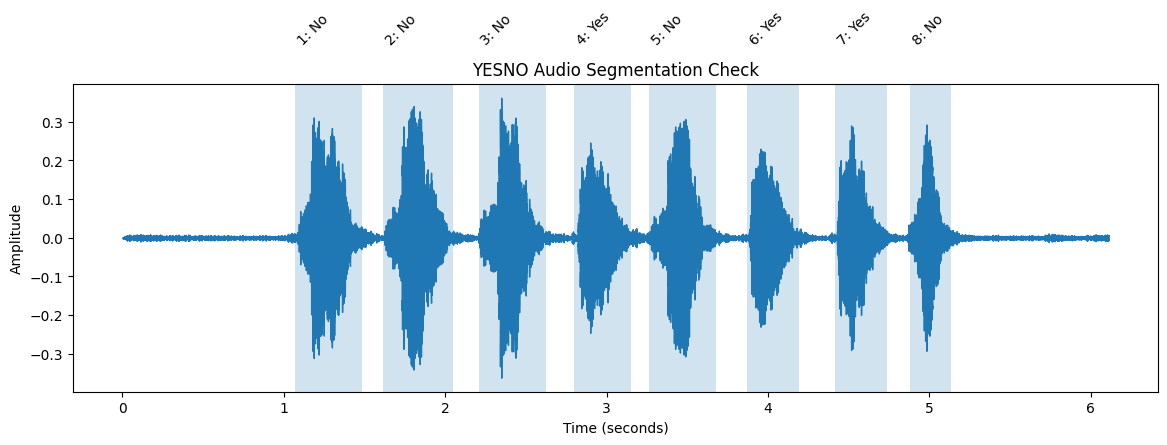

Original recording:


Individual segments:
Segment 1 - Expected: No


Segment 2 - Expected: No


Segment 3 - Expected: No


Segment 4 - Expected: Yes


Segment 5 - Expected: No


Segment 6 - Expected: Yes


Segment 7 - Expected: Yes


Segment 8 - Expected: No


In [18]:

# Step 15: Check segmentation visually and by listening

import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display
import os

# Select the first accepted recording
filename = next(
    f for f in sorted(wav_files)
    if f not in {name for name, count in issues}
)

audio, sample_rate = librosa.load(
    os.path.join(folder, filename), sr=None
)

intervals = librosa.effects.split(
    audio,
    top_db=25,
    frame_length=512,
    hop_length=128
)

labels = filename[:-4].split("_")

print("Recording:", filename)
print("Expected words:", len(labels))
print("Detected segments:", len(intervals))

plt.figure(figsize=(14, 4))
librosa.display.waveshow(audio, sr=sample_rate)

for i, (start, end) in enumerate(intervals):
    plt.axvspan(
        start / sample_rate,
        end / sample_rate,
        alpha=0.2
    )
    plt.text(
        start / sample_rate,
        0.5,
        f"{i+1}: {'Yes' if labels[i]=='1' else 'No'}",
        rotation=45
    )

plt.title("YESNO Audio Segmentation Check")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()

print("Original recording:")
display(Audio(audio, rate=sample_rate))

print("Individual segments:")
for i, (start, end) in enumerate(intervals):
    print(f"Segment {i+1} - Expected:",
          "Yes" if labels[i] == "1" else "No")
    display(Audio(audio[start:end], rate=sample_rate))


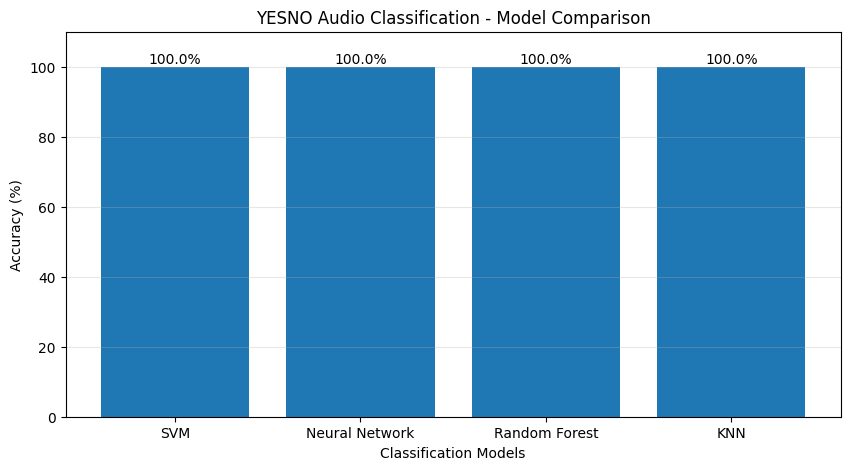

In [19]:

# Step 16: Compare Four Classifiers

import matplotlib.pyplot as plt

models = ["SVM", "Neural Network", "Random Forest", "KNN"]

accuracies = [
    svm_accuracy * 100,
    nn_accuracy * 100,
    rf_accuracy * 100,
    knn_accuracy * 100
]

plt.figure(figsize=(10, 5))
bars = plt.bar(models, accuracies)

plt.title("YESNO Audio Classification - Model Comparison")
plt.xlabel("Classification Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 110)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 1,
        f"{accuracy:.1f}%",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.show()
